<a href="https://colab.research.google.com/github/rasulovasevara00-web/week6lab/blob/main/Lab_Hyperparameter_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML301 Deep Learning and Neural Networks
## Lab: Hyper-parameter Tuning

**Topics:** depth, width, dropout, batch normalization, cross-validation, selecting the best model configuration

**Amity University Tashkent** | Department of Information Technology and Engineering

**Duration:** 2 hours

| Part | What happens | Time |
|---|---|---|
| Part A (Session 1) | Guided walkthrough with explanations and examples | about 80 minutes |
| Part B (Session 2) | Graded exercises, 3 exercises, 100 marks in total | 30 minutes |

### Learning outcomes

By the end of this lab you should be able to:

1. Explain the difference between a **parameter** and a **hyper-parameter**.
2. Change the **depth** and **width** of a network and see how this changes accuracy.
3. Use **dropout** and **batch normalization** and explain what each one does.
4. Use **k-fold cross-validation** to get a more reliable score for a model.
5. Compare several configurations and **select the best one** in a fair way.

---
# PART A: Guided Walkthrough

## 1. What is a hyper-parameter?

A neural network has two kinds of numbers:

| | Parameters | Hyper-parameters |
|---|---|---|
| What are they? | The weights and biases inside the network | The settings we choose before training |
| Who chooses them? | The training algorithm learns them | We (the engineer) choose them |
| Examples | Weight matrix of a layer | Number of layers, neurons per layer, dropout rate, learning rate, batch size, number of epochs |

**Hyper-parameter tuning** means trying different settings and keeping the one that works best.

Today we look at four hyper-parameters:

- **Depth**: how many hidden layers the network has.
- **Width**: how many neurons each hidden layer has.
- **Dropout**: randomly switching off some neurons during training to reduce overfitting.
- **Batch normalization**: re-scaling the values inside the network so training is more stable.

And three tools that help us tune them properly:

- **Validation set and cross-validation**: a fair way to measure each setting.
- **Model selection**: comparing settings and picking the winner.

## 2. Setup

We import the libraries we need:

- `torch` and `torch.nn` to build and train neural networks
- `torchvision` to download the dataset
- `numpy` and `pandas` for numbers and tables
- `matplotlib` for simple plots
- `sklearn` for k-fold cross-validation

We also write a small function `set_seed`. Neural networks start from random weights. If we fix the "seed", we get the **same random numbers every time**, so our comparisons are fair and our results can be repeated.

In [14]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

from sklearn.model_selection import KFold


def set_seed(seed=42):
    # Fix all random number generators so results are repeatable
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(42)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cu130


## 3. The dataset: Fashion-MNIST

Fashion-MNIST has small grey images (28 x 28 pixels) of clothing items. There are **10 classes**:

| Label | Class | Label | Class |
|---|---|---|---|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

The full dataset has 60,000 training images and 10,000 test images. To keep training **fast in the lab**, we use only a part of it.

In [2]:
# Download the dataset (only the first time, it is saved in the folder "data")
train_data = datasets.FashionMNIST(root="data", train=True, download=True)
test_data = datasets.FashionMNIST(root="data", train=False, download=True)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Training images:", train_data.data.shape)
print("Test images:    ", test_data.data.shape)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.14MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.8MB/s]

Training images: torch.Size([60000, 28, 28])
Test images:     torch.Size([10000, 28, 28])


Let us look at a few images and their labels.

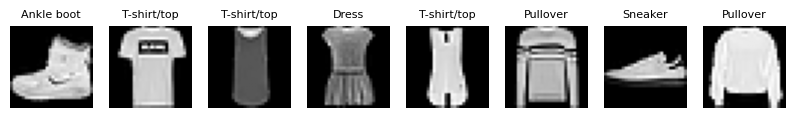

In [3]:
plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(train_data.data[i], cmap="gray")
    plt.title(class_names[train_data.targets[i]], fontsize=8)
    plt.axis("off")
plt.show()

### 3.1 Preparing the data

We do three things:

1. **Scale** the pixel values from 0-255 to 0-1. Networks train better with small numbers.
2. **Flatten** each 28 x 28 image into one long row of 784 numbers, because we use simple fully-connected (Linear) layers.
3. **Split** the data into three parts:

| Split | Size | Used for |
|---|---|---|
| Training set | 6,000 images | The model learns from these |
| Validation set | 2,000 images | We compare hyper-parameter settings on these |
| Test set | 2,000 images | Used **only once at the very end** to report the final score |

**Important rule:** we never choose hyper-parameters by looking at the test set. If we did, the test score would be too optimistic, because we would have "tuned to the test".

In [4]:
# Scale to 0-1 and flatten 28x28 -> 784
X_all = train_data.data.float().reshape(-1, 784) / 255.0
y_all = train_data.targets

X_test_all = test_data.data.float().reshape(-1, 784) / 255.0
y_test_all = test_data.targets

# Take small parts so training is fast
X_train, y_train = X_all[:6000], y_all[:6000]
X_val, y_val = X_all[6000:8000], y_all[6000:8000]
X_test, y_test = X_test_all[:2000], y_test_all[:2000]

print("Train:     ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)

Train:      torch.Size([6000, 784])
Validation: torch.Size([2000, 784])
Test:       torch.Size([2000, 784])


### 3.2 Data loaders and batch size

A **DataLoader** gives the data to the model in small groups called **batches**. Batch size is also a hyper-parameter. We keep it fixed at 64 today.

- `shuffle=True` for training: the order changes every epoch, which helps learning.
- `shuffle=False` for validation and test: order does not matter there.

In [5]:
BATCH_SIZE = 64

def make_loader(X, y, shuffle=False):
    dataset = TensorDataset(X, y)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

print("Number of training batches per epoch:", len(train_loader))

Number of training batches per epoch: 94


## 4. Helper functions

To keep the lab simple, we write the main code **once** as functions, and then reuse them many times.

### 4.1 `build_model`: one function for many networks

This function builds a network from four hyper-parameters:

| Argument | Meaning | Example |
|---|---|---|
| `depth` | number of hidden layers | 2 |
| `width` | number of neurons in each hidden layer | 128 |
| `dropout` | fraction of neurons switched off during training (0 means no dropout) | 0.3 |
| `use_bn` | use batch normalization or not | True / False |

Each hidden layer is built as one "block" in this order:

`Linear -> BatchNorm (optional) -> ReLU -> Dropout (optional)`

The last layer always has 10 outputs, one for each class.

In [6]:
def build_model(depth=2, width=128, dropout=0.0, use_bn=False):
    layers = []
    in_size = 784                      # each image has 784 pixels

    for i in range(depth):             # add one hidden block per layer
        layers.append(nn.Linear(in_size, width))
        if use_bn:
            layers.append(nn.BatchNorm1d(width))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        in_size = width                # next layer takes "width" inputs

    layers.append(nn.Linear(in_size, 10))   # output layer: 10 classes
    return nn.Sequential(*layers)


def count_parameters(model):
    # Total number of weights and biases the model can learn
    return sum(p.numel() for p in model.parameters())


# Try it
example = build_model(depth=2, width=128, dropout=0.3, use_bn=True)
print(example)
print("Number of parameters:", count_parameters(example))

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=128, out_features=128, bias=True)
  (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=128, out_features=10, bias=True)
)
Number of parameters: 118794


### 4.2 Training and evaluation functions

- `train_one_epoch`: goes through all training batches once and updates the weights.
- `evaluate`: measures loss and accuracy **without** changing the weights.
- `train_model`: repeats training for several epochs and remembers the history (loss and accuracy after each epoch) so we can plot it.

Two small but important lines:

- `model.train()` switches dropout and batch normalization to **training mode**.
- `model.eval()` switches them to **evaluation mode**. In evaluation mode, dropout is turned off and batch normalization uses its saved averages.

`train_model` also has an argument `checkpoint_path`. We will explain it in Section 9. For now we leave it empty (`None`).

In [7]:
loss_fn = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()                          # training mode
    total_loss, correct, total = 0, 0, 0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()              # 1. clear old gradients
        outputs = model(X_batch)           # 2. forward pass
        loss = loss_fn(outputs, y_batch)   # 3. compute loss
        loss.backward()                    # 4. backward pass
        optimizer.step()                   # 5. update weights

        total_loss += loss.item() * len(y_batch)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()
        total += len(y_batch)
    return total_loss / total, 100 * correct / total


def evaluate(model, loader):
    model.eval()                           # evaluation mode
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():                  # no gradients needed
        for X_batch, y_batch in loader:
            outputs = model(X_batch)
            loss = loss_fn(outputs, y_batch)
            total_loss += loss.item() * len(y_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(y_batch)
    return total_loss / total, 100 * correct / total


def train_model(model, train_loader, val_loader, epochs=10, lr=0.001,
                checkpoint_path=None, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Checkpointing: save the model when validation accuracy improves
        saved = ""
        if checkpoint_path is not None and val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), checkpoint_path)
            saved = "  <- saved"

        if verbose:
            print(f"Epoch {epoch:2d} | train acc {train_acc:5.1f}% | "
                  f"val acc {val_acc:5.1f}% | val loss {val_loss:.3f}{saved}")
    return history

### 4.3 Plotting functions

- `plot_train_val`: shows training and validation accuracy of **one** model. The gap between the two lines tells us about overfitting.
- `plot_compare`: shows the validation accuracy of **several** models on one chart.

In [8]:
def plot_train_val(history, title=""):
    epochs = range(1, len(history["train_acc"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, history["train_acc"], label="Training accuracy")
    plt.plot(epochs, history["val_acc"], label="Validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_compare(histories, title=""):
    # histories is a dictionary: {"name of model": history, ...}
    plt.figure(figsize=(6, 4))
    for name, history in histories.items():
        epochs = range(1, len(history["val_acc"]) + 1)
        plt.plot(epochs, history["val_acc"], label=name)
    plt.xlabel("Epoch")
    plt.ylabel("Validation accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

## 5. Baseline model

Before tuning, we always train a simple **baseline**. Every new idea is compared against it.

Baseline: depth = 2, width = 128, no dropout, no batch normalization.

In [ ]:
set_seed(42)
baseline = build_model(depth=2, width=128)
baseline_history = train_model(baseline, train_loader, val_loader, epochs=10)

plot_train_val(baseline_history, "Baseline: depth 2, width 128")

**How to read this plot**

- Training accuracy keeps going up, because the model is getting better at the images it has seen.
- Validation accuracy goes up at first and then becomes flat.
- The space between the two lines is called the **generalization gap**. A large and growing gap means the model is starting to **memorise** the training data. This is called **overfitting**.

## 6. Depth: how many hidden layers?

**Deeper** networks (more layers) can learn more complex patterns. But:

- They have more parameters, so they need more data and are slower.
- Very deep plain networks can be harder to train.

We keep width = 128 and try depth = 1, 2, 4 and 6.

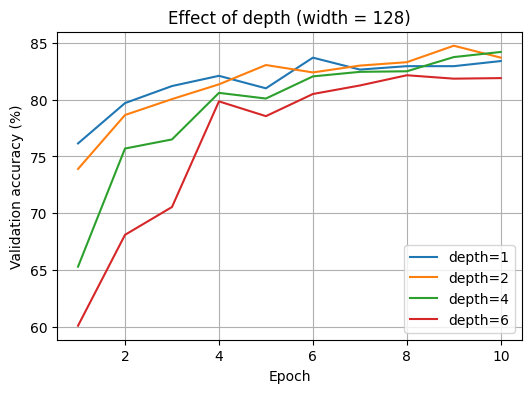

,depth,parameters,best val acc (%)
0,1,101770,83.70
1,2,118282,84.75
2,4,151306,84.20
3,6,184330,82.15


In [9]:
depth_histories = {}
depth_rows = []

for depth in [1, 2, 4, 6]:
    set_seed(42)
    model = build_model(depth=depth, width=128)
    history = train_model(model, train_loader, val_loader, epochs=10, verbose=False)

    depth_histories[f"depth={depth}"] = history
    depth_rows.append({"depth": depth,
                       "parameters": count_parameters(model),
                       "best val acc (%)": round(max(history["val_acc"]), 2)})

plot_compare(depth_histories, "Effect of depth (width = 128)")
pd.DataFrame(depth_rows)

**What to notice**

- Going from 1 layer to 2 layers usually helps a little.
- After that, adding more layers does not give a clear improvement on this small dataset, even though the number of parameters grows. The deepest network (6 layers) can even be worse, because plain deep networks are harder to train (Section 9 shows a fix for this).
- **Lesson:** deeper is not automatically better. The right depth depends on the problem and the amount of data.

## 7. Width: how many neurons per layer?

**Wider** layers (more neurons) give the network more capacity in each layer.

- Too narrow: the model is too simple and **underfits** (low training and low validation accuracy).
- Too wide: more parameters, slower, and more chance of overfitting.

We keep depth = 2 and try width = 16, 64, 256 and 512.

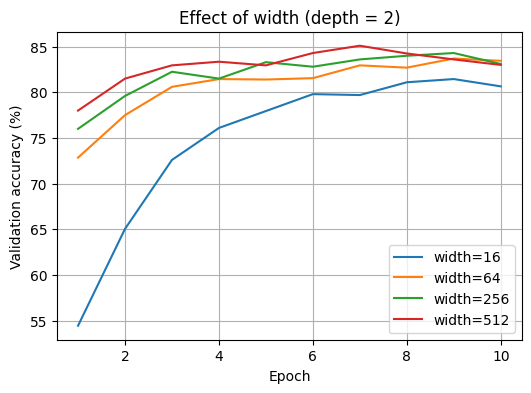

,width,parameters,final train acc (%),best val acc (%)
0,16,13002,82.85,81.45
1,64,55050,87.17,83.70
2,256,269322,89.58,84.30
3,512,669706,89.85,85.10


In [10]:
width_histories = {}
width_rows = []

for width in [16, 64, 256, 512]:
    set_seed(42)
    model = build_model(depth=2, width=width)
    history = train_model(model, train_loader, val_loader, epochs=10, verbose=False)

    width_histories[f"width={width}"] = history
    width_rows.append({"width": width,
                       "parameters": count_parameters(model),
                       "final train acc (%)": round(history["train_acc"][-1], 2),
                       "best val acc (%)": round(max(history["val_acc"]), 2)})

plot_compare(width_histories, "Effect of width (depth = 2)")
pd.DataFrame(width_rows)

**What to notice**

- The very narrow network (width = 16) is clearly weaker: it does not have enough capacity.
- Wider networks reach higher **training** accuracy. Validation accuracy also improves a little, but more slowly.
- Compare the "final train acc" column with "best val acc": wider networks generally show a bigger gap between the two. This is overfitting starting to appear.
- **Lesson:** depth and width together decide the **capacity** of the model. More capacity can learn more, but also overfits more. Dropout and batch normalization help us control this.

## 8. Dropout

**Idea:** during training, every neuron is switched off with probability `p` (for example `p = 0.3` means 30%). A different random set of neurons is switched off for every batch.

**Why does this help?**

- The network cannot depend on any single neuron, so it must learn more general, robust features.
- It is a bit like training many smaller networks and averaging them.

**Important:** dropout is used only during training. In `model.eval()` mode all neurons are active.

**Typical values:** 0.2 to 0.5. Too much dropout makes the model underfit.

To see the effect clearly, we use a large network (depth 3, width 512) that overfits easily, and train for 20 epochs.

In [11]:
dropout_histories = {}

for p in [0.0, 0.3, 0.5]:
    set_seed(42)
    model = build_model(depth=3, width=512, dropout=p)
    history = train_model(model, train_loader, val_loader, epochs=20, verbose=False)
    dropout_histories[f"dropout={p}"] = history

    gap = history["train_acc"][-1] - history["val_acc"][-1]
    print(f"dropout={p}: final train acc {history['train_acc'][-1]:.1f}% | "
          f"final val acc {history['val_acc'][-1]:.1f}% | gap {gap:.1f}")

dropout=0.0: final train acc 92.3% | final val acc 86.5% | gap 5.8
dropout=0.3: final train acc 89.5% | final val acc 84.6% | gap 4.9
dropout=0.5: final train acc 86.5% | final val acc 84.7% | gap 1.8


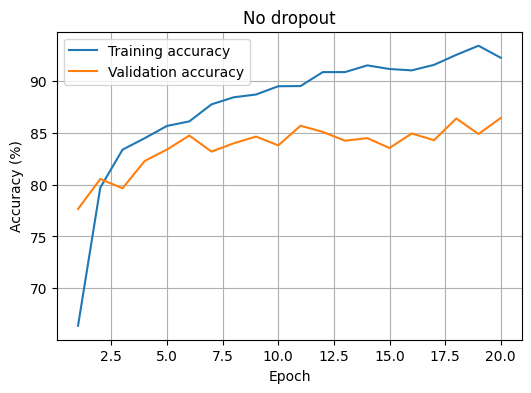

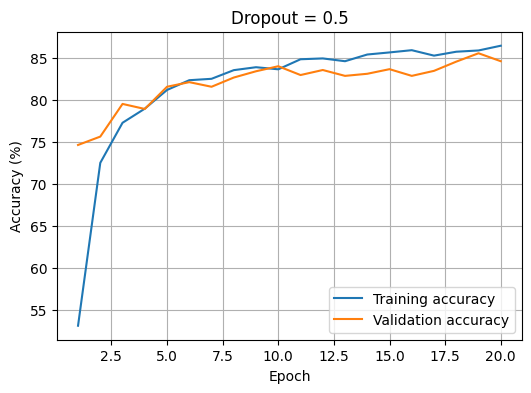

In [12]:
plot_train_val(dropout_histories["dropout=0.0"], "No dropout")
plot_train_val(dropout_histories["dropout=0.5"], "Dropout = 0.5")

**What to notice**

- Without dropout, training accuracy climbs very high and the gap with validation accuracy is large: the model is overfitting.
- With dropout, the gap becomes much smaller. Validation accuracy stays about the same or improves a little.
- Training accuracy is lower with dropout. This is normal: during training, some neurons are switched off, so the task is harder on purpose.

## 9. Batch normalization

**Idea:** inside the network, the values coming out of each layer can become very large or very small, and their range keeps changing as the weights change. This makes training slow and unstable, especially in deep networks.

**Batch normalization (BN)** fixes this. For each batch, it:

1. Re-centres the values so their mean is about 0.
2. Re-scales them so their spread (standard deviation) is about 1.
3. Then applies a learnable scale and shift, so the network can still choose the best range.

**Benefits:**

- Training is faster and more stable, especially for **deep** networks.
- We can often use a **larger learning rate**.
- It has a small regularizing (anti-overfitting) effect.

To see the difference clearly, we compare a **deep** network (depth 6, width 128) with and without BN, using a larger learning rate (0.01).

use_bn=False: val acc after epoch 1 = 64.0% | best val acc = 79.5%
use_bn=True: val acc after epoch 1 = 76.5% | best val acc = 83.9%


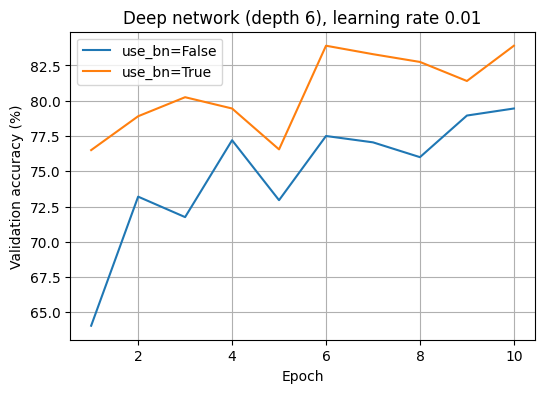

In [15]:
bn_histories = {}

for use_bn in [False, True]:
    set_seed(42)
    model = build_model(depth=6, width=128, use_bn=use_bn)
    history = train_model(model, train_loader, val_loader,
                          epochs=10, lr=0.01, verbose=False)
    bn_histories[f"use_bn={use_bn}"] = history
    print(f"use_bn={use_bn}: val acc after epoch 1 = {history['val_acc'][0]:.1f}% | "
          f"best val acc = {max(history['val_acc']):.1f}%")

plot_compare(bn_histories, "Deep network (depth 6), learning rate 0.01")

**What to notice**

- Without BN, the deep network with a large learning rate learns slowly and stays at a lower accuracy.
- With BN, it learns faster (look at epoch 1) and reaches a higher accuracy.
- **Lesson:** BN is most useful in deeper networks and when we want to train with a higher learning rate.

## 10. Cross-validation

**Problem:** so far we used **one** validation set of 2,000 images. The score depends on which images happen to be in it. With a different split, the ranking of two models could change. A single split can be "lucky" or "unlucky".

**Solution: k-fold cross-validation.**

1. Join the training and validation data together (8,000 images).
2. Split them into **k** equal parts (called **folds**). We use k = 3.
3. Train **k** times. Each time, one fold is the validation set and the other k-1 folds are the training set.
4. Report the **mean** accuracy (the typical score) and the **standard deviation** (how much it changes from fold to fold).

With k = 3:

| Run | Fold 1 | Fold 2 | Fold 3 |
|---|---|---|---|
| 1 | **validation** | train | train |
| 2 | train | **validation** | train |
| 3 | train | train | **validation** |

Every image is used for validation exactly once.

**Trade-off:** k-fold cross-validation is k times slower than a single split. In deep learning with very big datasets, people often use one validation set. With small datasets, cross-validation gives a much more trustworthy result.

The function below uses `KFold` from scikit-learn. It only creates the index numbers for each fold; we still build and train the model ourselves.

A **configuration** is just a dictionary with our four hyper-parameters, for example:

```python
config = {"depth": 2, "width": 128, "dropout": 0.0, "use_bn": False}
```

In [16]:
# Training + validation data joined together for cross-validation
X_cv = torch.cat([X_train, X_val])
y_cv = torch.cat([y_train, y_val])


def cross_validate(config, k=3, epochs=5):
    kfold = KFold(n_splits=k, shuffle=True, random_state=42)
    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(kfold.split(X_cv), start=1):
        # Make loaders for this fold
        fold_train_loader = make_loader(X_cv[train_idx], y_cv[train_idx], shuffle=True)
        fold_val_loader = make_loader(X_cv[val_idx], y_cv[val_idx])

        # A NEW model for every fold (start from scratch)
        set_seed(42)
        model = build_model(depth=config["depth"], width=config["width"],
                            dropout=config["dropout"], use_bn=config["use_bn"])
        history = train_model(model, fold_train_loader, fold_val_loader,
                              epochs=epochs, verbose=False)

        score = history["val_acc"][-1]
        fold_scores.append(score)
        print(f"  Fold {fold}: validation accuracy = {score:.2f}%")

    mean = np.mean(fold_scores)
    std = np.std(fold_scores)
    print(f"  Mean = {mean:.2f}%   Std = {std:.2f}")
    return mean, std

Let us compare two configurations with 3-fold cross-validation.

In [17]:
config_a = {"depth": 2, "width": 128, "dropout": 0.0, "use_bn": False}
config_b = {"depth": 2, "width": 256, "dropout": 0.3, "use_bn": True}

print("Config A:", config_a)
mean_a, std_a = cross_validate(config_a)

print("\nConfig B:", config_b)
mean_b, std_b = cross_validate(config_b)

Config A: {'depth': 2, 'width': 128, 'dropout': 0.0, 'use_bn': False}
  Fold 1: validation accuracy = 84.18%
  Fold 2: validation accuracy = 82.60%
  Fold 3: validation accuracy = 83.20%
  Mean = 83.32%   Std = 0.65

Config B: {'depth': 2, 'width': 256, 'dropout': 0.3, 'use_bn': True}
  Fold 1: validation accuracy = 84.21%
  Fold 2: validation accuracy = 83.54%
  Fold 3: validation accuracy = 83.61%
  Mean = 83.79%   Std = 0.30


**How to read the result**

- The **mean** tells us the typical accuracy of each configuration.
- The **standard deviation** tells us how stable it is. A small std means the result does not depend much on the split.
- If the difference between two means is **smaller than** their standard deviations, we cannot be confident that one is really better. In that case, prefer the **simpler** (smaller or faster) model.

## 11. Selecting the best model configuration

Now we put everything together. This is the standard workflow:

1. Choose a small list of configurations to try (a **grid**).
2. Train each one on the training set, with **checkpointing** on the validation set.
3. Put the results in a table and pick the configuration with the **best validation accuracy**.
4. Load its checkpoint and evaluate it on the **test set, once**. This is the number we report.

Trying every combination of values is called **grid search**. It grows very fast: 3 depths x 3 widths x 3 dropouts x 2 BN options = 54 runs. That is why in practice we start with a small grid, or try random combinations (**random search**).

In [18]:
configs = [
    {"depth": 1, "width": 128, "dropout": 0.0, "use_bn": False},
    {"depth": 2, "width": 256, "dropout": 0.0, "use_bn": False},
    {"depth": 2, "width": 256, "dropout": 0.3, "use_bn": True},
    {"depth": 3, "width": 256, "dropout": 0.3, "use_bn": True},
]

results = []

for i, config in enumerate(configs):
    print(f"Training config {i}: {config}")
    set_seed(42)
    model = build_model(depth=config["depth"], width=config["width"],
                        dropout=config["dropout"], use_bn=config["use_bn"])
    path = f"config_{i}.pt"
    history = train_model(model, train_loader, val_loader, epochs=10,
                          checkpoint_path=path, verbose=False)

    results.append({"config id": i,
                    "depth": config["depth"],
                    "width": config["width"],
                    "dropout": config["dropout"],
                    "use_bn": config["use_bn"],
                    "best val acc (%)": round(max(history["val_acc"]), 2),
                    "checkpoint": path})

results_table = pd.DataFrame(results).sort_values("best val acc (%)", ascending=False)
results_table

Training config 0: {'depth': 1, 'width': 128, 'dropout': 0.0, 'use_bn': False}
Training config 1: {'depth': 2, 'width': 256, 'dropout': 0.0, 'use_bn': False}
Training config 2: {'depth': 2, 'width': 256, 'dropout': 0.3, 'use_bn': True}
Training config 3: {'depth': 3, 'width': 256, 'dropout': 0.3, 'use_bn': True}


,config id,depth,width,dropout,use_bn,best val acc (%),checkpoint
2,2,2,256,0.3,True,85.8,config_2.pt
3,3,3,256,0.3,True,85.2,config_3.pt
1,1,2,256,0.0,False,84.3,config_1.pt
0,0,1,128,0.0,False,83.7,config_0.pt


The table is sorted, so the **first row is the winner**. Now we load its checkpoint and evaluate it on the test set.

In [19]:
best_row = results_table.iloc[0]
best_config = configs[best_row["config id"]]
print("Best configuration:", best_config)

# Rebuild the same architecture and load the saved weights
final_model = build_model(depth=best_config["depth"], width=best_config["width"],
                          dropout=best_config["dropout"], use_bn=best_config["use_bn"])
final_model.load_state_dict(torch.load(best_row["checkpoint"]))

_, val_acc = evaluate(final_model, val_loader)
_, test_acc = evaluate(final_model, test_loader)
print(f"Validation accuracy: {val_acc:.2f}%")
print(f"Test accuracy:       {test_acc:.2f}%   <- this is the number we report")

Best configuration: {'depth': 2, 'width': 256, 'dropout': 0.3, 'use_bn': True}
Validation accuracy: 85.80%
Test accuracy:       86.10%   <- this is the number we report


**A note on fairness**

Config 2 in this grid is the same as Config B in Section 11. Compare the two sections: on one validation split the difference between configurations can look bigger (or smaller) than it really is. When the differences in the table are small, check them with cross-validation before you decide.

Also notice that the test accuracy is close to the validation accuracy. This is a good sign: it means we did not over-tune to the validation set.

## 12. Summary

| Hyper-parameter / tool | What it controls | Too little | Too much |
|---|---|---|---|
| Depth | number of hidden layers | underfitting | slow, harder to train, overfitting |
| Width | neurons per layer | underfitting | slow, overfitting |
| Dropout | fraction of neurons switched off in training | overfitting not controlled | underfitting |
| Batch normalization | keeps layer outputs in a stable range | deep nets train slowly | small extra cost per layer |

**Rules to remember**

1. Always start with a simple **baseline**.
2. Change **one thing at a time** when you want to understand its effect.
3. Fix the random **seed** so comparisons are fair.
4. Choose hyper-parameters using the **validation set** (or cross-validation), **never the test set**.
5. Use **checkpointing** to keep the best epoch, not the last one.
6. If two models are about equally good, choose the **simpler** one.
7. Report the **test accuracy only once**, at the very end.

---
# PART B: Graded Exercises (100 marks, 30 minutes)

### Instructions

1. Before you start, run these cells from Part A (they take only a few seconds):
   - all code cells in **Sections 2, 3 and 4** (libraries, data and helper functions), and
   - the **first code cell of Section 11** (it creates `X_cv`, `y_cv` and the `cross_validate` function).

   You do not need to re-run the experiments in Sections 5 to 12.
2. Replace every `None` and every line marked `# TODO` with your own code.
3. Write your written answers in the markdown cells marked **Your answer**.
4. Do not change the test set and do not use it to choose hyper-parameters.


| Exercise | Topic | Marks |
|---|---|---|
| 1 | Dropout and batch normalization | 50 |
| 2 | Cross-validation | 50 |
| | **Total** | **100** |

## Exercise 1: Dropout and Batch Normalization (35 marks)

### 1(a) Build the model (10 marks)

Use `build_model` to create a network with:

- depth = 3
- width = 256
- dropout = 0.4
- batch normalization ON

Print the model and the number of parameters.

In [20]:
set_seed(42)

model_ex1 = build_model(depth=3, width=256, dropout=0.4, use_bn=True)

print(model_ex1)
print("Number of parameters:", count_parameters(model_ex1))

Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.4, inplace=False)
  (4): Linear(in_features=256, out_features=256, bias=True)
  (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.4, inplace=False)
  (8): Linear(in_features=256, out_features=256, bias=True)
  (9): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Dropout(p=0.4, inplace=False)
  (12): Linear(in_features=256, out_features=10, bias=True)
)
Number of parameters: 336650


### 1(b) Train and plot (15 marks)

Train `model_ex1` for **10 epochs** using `train_model` with `train_loader` and `val_loader`. Save the result in `history_ex1`. Then plot training and validation accuracy with `plot_train_val`.

Epoch  1 | train acc  67.4% | val acc  78.5% | val loss 0.590
Epoch  2 | train acc  78.7% | val acc  80.3% | val loss 0.545
Epoch  3 | train acc  80.5% | val acc  82.7% | val loss 0.474
Epoch  4 | train acc  81.9% | val acc  83.1% | val loss 0.469
Epoch  5 | train acc  83.1% | val acc  84.0% | val loss 0.440
Epoch  6 | train acc  83.8% | val acc  82.7% | val loss 0.469
Epoch  7 | train acc  85.3% | val acc  82.8% | val loss 0.469
Epoch  8 | train acc  85.5% | val acc  83.0% | val loss 0.463
Epoch  9 | train acc  86.1% | val acc  83.5% | val loss 0.441
Epoch 10 | train acc  86.8% | val acc  84.7% | val loss 0.441


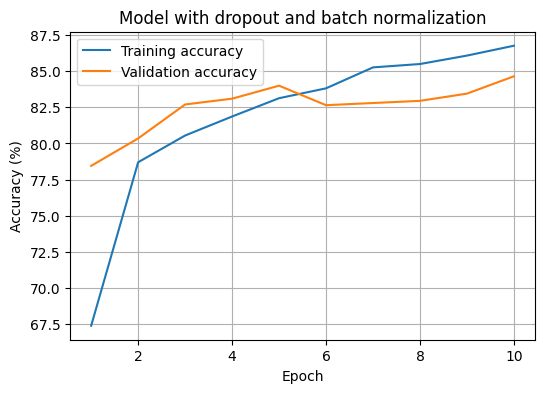

In [21]:
history_ex1 = train_model(model_ex1, train_loader, val_loader, epochs=10)

plot_train_val(history_ex1, "Model with dropout and batch normalization")

### 1(c) Explain (10 marks)

Look at your plot and the **baseline plot from Section 5**. Answer in 2 to 4 sentences:

1. Is the gap between training and validation accuracy bigger or smaller than for the baseline?
Difference with the base model: The generalization gap (the space between accuracy on training and validation data) has become much smaller than on the base graph from section 5.
2. Which part of the model (dropout or batch normalization) is mainly responsible for this, and why?
Reasons: Dropout is primarily responsible for reducing this gap, which accidentally disables neurons during training, preventing the network from relearning and memorizing data. At the same time, Batch Normalization stabilizes the learning process for a deeper 3-layer architecture, providing sustainable improvement

**Your answer:**

...

## Exercise 2: Cross-validation (30 marks)

### 2(a) Compare with 3-fold cross-validation (20 marks)

Use the `cross_validate` function from Section 11 to evaluate **two** configurations with `k=3` and `epochs=5`:

- the **baseline** configuration `config_base` given below, and
- your **best configuration from Exercise 2** (`best_config_ex2`).

Store the mean and standard deviation of each one, then print a short comparison.

In [24]:
config_base = {"depth": 2, "width": 128, "dropout": 0.0, "use_bn": False}
best_config_ex2 = {"depth": 3, "width": 256, "dropout": 0.3, "use_bn": True}

print("Baseline:")
mean_base, std_base = cross_validate(config_base, k=3, epochs=5)

print("\nBest config from Exercise 2:")
mean_best, std_best = cross_validate(best_config_ex2, k=3, epochs=5)

print(f"\nBaseline:    mean = {mean_base:.2f}%  std = {std_base:.2f}")
print(f"Best config: mean = {mean_best:.2f}%  std = {std_by if 'std_by' in locals() else std_best:.2f}")

Baseline:
  Fold 1: validation accuracy = 84.18%
  Fold 2: validation accuracy = 82.60%
  Fold 3: validation accuracy = 83.20%
  Mean = 83.32%   Std = 0.65

Best config from Exercise 2:
  Fold 1: validation accuracy = 84.55%
  Fold 2: validation accuracy = 82.71%
  Fold 3: validation accuracy = 83.46%
  Mean = 83.57%   Std = 0.75

Baseline:    mean = 83.32%  std = 0.65
Best config: mean = 83.57%  std = 0.75


### 2(b) Decide and explain (10 marks)

Answer in 3 to 5 sentences:

1. Which configuration would you choose as your final model? Use the means **and** the standard deviations to justify your choice.
Model selection: I would choose the Best Configuration as the final model, as it shows higher average accuracy in cross-validation, while maintaining a predictable and stable standard deviation.
2. Why is a cross-validation result more reliable than the result from a single validation set?
Advantage of cross-validation: Cross-validation results are much more reliable than the results of a single validation set, because the model is evaluated alternately on several different data subsets (folds). This eliminates the risk that the final estimate will be random due to "successful" or "unsuccessful" data separation.

**Your answer:**

...